# Does a Binance momentum burst leave the far tail underpriced, and can it be farmed?

## S0 · Summary

**Research question.** Does buying the tail opposite a Binance momentum burst (a short-lookback z above a threshold), only while its ask is not worse than the driftless Brownian fair value, earn a positive net PnL per entry after the fee and the 150 ms delay on Polymarket's 15-minute crypto Up/Down markets?

**The idea.** The owner's idea: a fast move (a 2-sigma burst) over-shoots the book, and the tail it leaves on the other end is where the cheap convexity is. The Brownian fair value is driftless and holds no momentum term, so it is the honest 'no-momentum' price a burst is measured against. The rule waits for a short-lookback z of at least a threshold, then buys the far tail, and refuses to pay more than the fair value for it. A token asking 4 cents pays 25 times if right; the fee there is under a third of a cent, so the cost of the bet is mostly the price. A burst can cut either way, so the trade is one rule on both sides.

| | |
|---|---|
| Market | Polymarket 15-minute crypto Up/Down (BTC, ETH, SOL, XRP), driven by Binance spot trades |
| The trade | every second from the cell's first decision to 5 s before the end, if the L-second Binance z crosses the threshold in either direction, buy USD 20 of the far tail (the token the burst left behind) 150 ms later at no worse than the ask seen at the decision, only while its ask is at most the Brownian fair value (plus the cell's buffer) and under the cell's tail ceiling; hold to expiry; one entry per window |
| Costs, always on | the market's own taker fee (rate x p x (1 - p), or the 20% maker rebate for a resting order), the exact ladder walked 150 ms after the decision, the venue's 5-share minimum |
| Money test | net USD per entry out of sample, with a 95% interval over 15-minute slots; win rate beside the share needed to break even; Sharpe; the deflated Sharpe for the number of cells tried |
| Days, in date order | train 09-30, 10-01, 10-02; validate 10-03, 10-04; test 10-05, 10-06 (read once) |
| Found means | the test interval of net per entry above zero, the placebo beaten, the planted peek caught, positive at 150 and 250 ms and at twice the fee, and the sizing gate cleared; otherwise a recorded miss |
| Pre-registration | run um-010 on the predmkts desk, committed before the engine ran |

The result and its gates are drawn by the last cells.

**Falsifier, written before the test days were read.** The study ends with NO MONEY if any line below holds.

| Id | The study ends if |
|---|---|
| F1 | the chosen cell's net per entry on the test days is zero or below, or its 95% interval over 15-minute slots includes zero |
| F2 | the cell does not beat the same instants with random sides (placebo, 95th percentile), or the planted peek is not caught |
| F3 | net per entry is not above zero at 150 ms and at 250 ms, or not above zero at twice the fee |
| F4 | the cell is not above zero on both test days, or not positive on the train days as well as the validation days |

**Prior art** (carried from the desk's books, read 2026-10-07; not re-read today [1])

| Source | What it found | What we take from it |
|---|---|---|
| um-005, the tail-buy cell of this search (2026-10-07) | The far tail bought unconditionally earns nothing after the fee; the ratio gate on the driftless fair value could not beat a coin flip on the registered test days | The null this candidate must beat: an unconditional tail buy is fair, and the momentum trigger is the new information |
| um-004, the price-signal study (B-0649) | The Up mid follows a Binance burst in 300 to 500 ms, so the book reprices a burst fast | A fade has to be quicker than the book, or the far tail must mean-revert past the burst |
| the 15-minute study (B-0642) | The driftless Brownian TWAP fair value reproduces the recorded outcome in 99.2% of 1,140 windows | The fair value is driftless by construction: it is the honest no-momentum price the burst is measured against |

In [1]:
from IPython.display import Markdown, display
S0_HANDLE = display(Markdown("_The summary card is drawn here when the run finishes._"), display_id=True)

**Does a Binance momentum burst leave the far tail underpriced, and can it be farmed?** · **NO SIZE**

**Research question** Does fading a Binance momentum burst into the far tail earn a positive net PnL per entry after the fee and a 150 ms delay?

NO SIZE, class B. 176 test entries net +240 USD (+1.37 each, 95% -2.70 to +6.66); win 7.4% vs 5.9% to break even.

**Implementation**

| | |
|:--|:--|
| Trade | Buy the far tail a Binance burst left behind, at no worse than fair v. |
| Venue | Polymarket 15m crypto Up/Down; Binance is input |
| Rule | z2\|L10\|fv-buf\|10c\|T300 |
| Size | USD 20 a trade, USD 1,000 book, 1x |
| Costs | taker fee 0.07 x p(1-p) or 20% maker rebate; +150 ms |
| Window | 09-30 to 10-06, 168h, 1 regime |

**The numbers that matter**

| At | Metric | Value | Bar | |
|:--|:--|--:|:--|:--|
| test | Net per entry | +1.37 USD | 95% -2.70 to +6.66 | FAIL |
| test | Net after costs | +240 USD | 176 entries | FAIL |
| test | Win rate | 7.4% | break-even 5.9% | INFO |
| test | Deflated Sharpe | 0.00 | at least 0.90 | FAIL |

**Money**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Net per entry | +1.37 USD | interval above 0 | FAIL |
| Before costs, per entry | +1.70 USD |  | INFO |
| Costs, per entry | 0.33 USD |  | INFO |
| Sharpe per entry | +0.043 |  | INFO |
| Sharpe, 15-minute slots | +7.7 |  | INFO |

**Is it real**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Placebo, 95th percentile | +1.48 | below the cell | FAIL |
| Planted peek | +7.58 | pays more | PASS |
| Days above zero | 2 of 2 | all | PASS |
| Positive on train days | yes | yes | PASS |
| Pooled other days, per entry | +0.04 | informational | INFO |

**Delay and cost**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| No delay, per entry | -0.30 |  | INFO |
| 150 ms, per entry | +1.37 | above 0 | PASS |
| 250 ms, per entry | +1.25 | above 0 | PASS |
| Fee x2 | +1.03 | above 0 | PASS |

**Risk, USD**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Deepest drawdown | -424 | book USD 1,000 | INFO |
| Worst day | +88 |  | INFO |
| Fills a day | 88 |  | INFO |
| Net a day | +120 |  | INFO |

**Checks**

| Metric | Value | Bar | |
|:--|--:|:--|:--|
| Windows with a book | 94% | 90% bar | PASS |
| Cells tried | 144 |  | INFO |
| Engine checks held | 12 of 12 | all | INFO |

**Size**

| Size | Net, USD | Per entry | Verdict |
|:--|--:|--:|:--|
| 1x info only | +240 | +1.37 | FAIL |

Registered as um-010 before the engine ran; 144 cells on the train and validation days, the test days read once.  
The Polymarket days are those of um-003 and um-004: one window, one regime, not an independent observation.  
168h, 12/12 checks; Binance and Polymarket clocks taken as one.


## S1 · Setup

### S1.1 · Parameters

In [2]:
# ---- parameters: ours, never a venue number (the fee, the delay and the minimum order are S1.2) ----
STUDY_ID = "2026-10-08-predmkts-binance-15m-updown-momentum-tail"
KIND = "strategy"
DESK = "lab/predmkts"
RUN_ID = "um-010"
TITLE = "Does a Binance momentum burst leave the far tail underpriced, and can it be farmed?"
QUESTION = "Does fading a Binance momentum burst into the far tail earn a positive net PnL per entry after the fee and a 150 ms delay?"
SEED = 7
TRAIN_DAYS = ('2026-09-30', '2026-10-01', '2026-10-02')
VALIDATE_DAYS = ('2026-10-03', '2026-10-04')
TEST_DAYS = ('2026-10-05', '2026-10-06')
EXTRA_DAYS = {'earlier week': ('2026-09-23', '2026-09-24', '2026-09-25', '2026-09-26', '2026-09-27', '2026-09-28', '2026-09-29'), 'fresh day': ('2026-10-07',)}
CAND_MODULE, CAND_CLASS = "tf15_cands", "MomentumTail"
CLIP_USD = 20.0
BOOK_USD = 1000.0
LAT_MS = 150

### S1.2 · Assumptions

| Item | Value | Source |
|---|---|---|
| Taker delay | 150 ms between the decision and the order meeting the book | venue changelog 2026-09-04 [1]; the owner's brief |
| Taker fee | shares x rate x p x (1 - p), each market's own rate (0.07 on every market read) and exponent 1 | venue fact `fee.formula` [1]; market rows [API] |
| Maker rebate | 20% of the taker fee the counterparty pays, no maker fee | venue fact `fee.category_rates` [1], read 2026-10-04 |
| Minimum order | 5 shares | market rows [API] |
| Clip and book | USD 20 a trade, USD 1,000 book, 1x, one position per window (a resting order: one fill per side per window) | the brief |
| Fill (taker) | the ask ladder of the book row as of decision + 150 ms, four levels, best first, never above the rule's limit | design |
| Fill (resting) | joins the back of the queue (the displayed size at its price is ahead of it and never cancels); fills only from printed trades at or through its price; a cancel lands 150 ms after the Binance event that triggers it | design, conservative |
| Fair value | Brownian P(Up) of the Chainlink 60 s TWAP rule from the Binance trade-implied mid, volatility the 300 s half-life EWMA of 10 s squared returns | the 15-minute study (B-0642) |
| Outcome | the market's own recorded resolution | market rows [API] |
| Clocks | Binance trade time and the venue's book time taken as one clock | caveat |

In [3]:
# ---- the PROSE check: the numbers the S1 tables state, held to the code ----
import tf15_bt as B, tf15_mk as MK, tf15_table as TT, tf15_study as STUDYM
PROSE = {"delay": (TT.FILL_MS, LAT_MS), "clip": (B.CLIP_USD, CLIP_USD), "min shares": (B.MIN_SHARES, 5.0), "rebate": (MK.REBATE, 0.20), "cancel latency": (MK.CANCEL_LAT_MS, 150), "levels": (TT.L, 4)}
BAD = {k_: v_ for k_, (v_, w_) in PROSE.items() if v_ != w_}
assert not BAD, f"the S1 tables no longer describe this run: {BAD}"
print(f"S1 tables: {len(PROSE)} stated numbers equal the code")

S1 tables: 6 stated numbers equal the code


### S1.3 · Data

Every input is a pinned or stored day read through `fundplat.data`: the Binance spot trades (`ticks.day_frame`) and the exact Up-token ladders of every 15-minute market (`updown15_pin.read`, pinned once by the platform's ladder job). One table per day is derived from them and seated in `fundplat.data.derived` (`tf15_runner.py`); the notebook loads those tables.

| source | what | window | guard |
|---|---|---|---|
| `ticks.day_frame` | Binance spot aggTrades BTC, ETH, SOL, XRP | the days of S1.1 and the day before each | the file checksum in the day's meta |
| `updown15_pin.read` | Polymarket Up-token ladder after every event, all four coins | the days of S1.1 | the platform's day manifest digest |
| `updown15.markets` | the market list with fee schedule, reference price and recorded outcome | the days of S1.1 | the platform's coverage check |

In [4]:
import datetime as dt, json, math, time
import numpy as np, pandas as pd
from IPython.display import HTML, Markdown, display
from fundplat.quant.core import figstyle, report as REPORT, summary_card
import tf15_cands as CANDS, tf15_report as RP, tf15_figs as FIGS, tf15_runner as RUNNER, lift_figs as LF
get_ipython().run_line_magic("config", "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
LF.setup()
RUN_AT = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%MZ")
print("loading the seated decision tables (fundplat.data.derived) for", TRAIN_DAYS + VALIDATE_DAYS + TEST_DAYS)
t0 = time.time()
TABS = {"train": B.Tab(TRAIN_DAYS), "validate": B.Tab(VALIDATE_DAYS), "test": B.Tab(TEST_DAYS)}
print({k_: f"{v_.W} windows" for k_, v_ in TABS.items()}, f"{time.time() - t0:.0f}s")
DAYS_ALL = TRAIN_DAYS + VALIDATE_DAYS + TEST_DAYS
HOURS_ALL = 24 * len(DAYS_ALL)
WINDOW = {"from": f"{DAYS_ALL[0]}T00:00Z", "to": f"{(dt.date.fromisoformat(DAYS_ALL[-1]) + dt.timedelta(days=1)).isoformat()}T00:00Z", "hours": HOURS_ALL, "regimes": 1}
pct = lambda v, d=1: f"{v * 100:.{d}f}%"
sgn = lambda v, d=2: f"{v:+,.{d}f}"
usd = lambda v, d=0: f"USD {v:,.{d}f}"
WIN_ALL = f"{DAYS_ALL[0][5:]} to {DAYS_ALL[-1][5:]} · {HOURS_ALL}h · 4 coins"
WIN_VAL = f"{VALIDATE_DAYS[0][5:]} to {VALIDATE_DAYS[-1][5:]} · {24 * len(VALIDATE_DAYS)}h · validation days"
WIN_TEST = f"{TEST_DAYS[0][5:]} to {TEST_DAYS[-1][5:]} · {24 * len(TEST_DAYS)}h · test days"
FIGURES, GATES, CAVEATS = [], [], []
CAND = getattr(__import__(CAND_MODULE), CAND_CLASS)()
assert CAND.id == "c5-momentum-tail", CAND.id
assert False or (max(TRAIN_DAYS) < min(VALIDATE_DAYS) and max(VALIDATE_DAYS) < min(TEST_DAYS)), "the split is not in date order"

loading the seated decision tables (fundplat.data.derived) for ('2026-09-30', '2026-10-01', '2026-10-02', '2026-10-03', '2026-10-04', '2026-10-05', '2026-10-06')


{'train': '1089 windows', 'validate': '721 windows', 'test': '721 windows'} 1s


### S1.4 · Runs

The engine checks run here; every one that can fail is counted.

In [5]:
import tf15_fv as FVMOD
print("tf15_bt:"); ok_bt = B.selftest()
print("tf15_fv:"); ok_fv = FVMOD.selftest()
print("tf15_mk:"); ok_mk = MK.selftest()
assert ok_bt and ok_fv and ok_mk, "an engine check failed"
VERIFY = {"suite": "tf15 engine checks and planted tests", "passed": 11, "total": 11, "books": sum(t_.W for t_ in TABS.values())}      # 5 + 2 + 4 engine cases above; the planted peek of S4 adds one

tf15_bt:
  ok   walk takes 10 at 0.50, 20 at 0.52 and 8.36 at 0.55 for 20 USD
  ok   walk never pays above the limit (second row stops at 0.50)
  ok   fee is rate x p x (1 - p) per share (10 sh at 0.50 -> 0.175)
  ok   sell 8 into bids 5 at 0.40 and 3 at 0.30 -> proceeds 2.9
  ok   slot bootstrap of a constant has a zero-width interval
tf15_fv:
  ok   equals updown15_model.twap_p with the extras off (max diff 0.0e+00)
  ok   basis noise keeps a 1 bp lead at 2 s left below certainty (p 0.841; without it 1.000)
tf15_mk:
  ok   posts at second 10, fills 45 printed - 30 ahead = 15 of 40 shares at 0.48
  ok   a print at 0.50 (above the bid) is not a fill; the rebate is 20% of the taker fee
  ok   a cancel at the first adverse event (30.0 s + 150 ms) leaves the later prints unfilled
  ok   prints inside the cancel latency still fill it (adverse selection is paid)


## S2 · Data checks

| question | gate to S3 |
|---|---|
| Is there a book for the windows, is the table the pinned ladder read without looking ahead, and do the engine's planted tests behave? | at least 90% of windows have a book; a planted peek pays far more than random sides |

In [6]:
# ---- coverage of the tables: windows with a book by the first decision second, and the Binance reference against the venue's published one ----
COV = []
for role_, tab_ in TABS.items():
    for i_, d_ in enumerate(tab_.days):
        arrs_, meta_ = RUNNER.load(d_)
        COV.append(dict(role=role_, day=d_, windows=int(meta_["windows"]), with_book=int(meta_["ok"]), share=meta_["ok"] / meta_["windows"]))
COV = pd.DataFrame(COV)
display(Markdown("**Windows with a book by the first decision second** (the other windows have no ladder, or a Binance gap over 30 s, and are out before any outcome is read)\n\n| Role | Day | Windows | With a book | Share |\n|---|---|---|---|---|\n" +
                 "\n".join(f"| {r.role} | {r.day} | {r.windows} | {r.with_book} | {pct(r.share)} |" for r in COV.itertuples())))
SHARE = float(COV.with_book.sum() / COV.windows.sum())
_t = TABS["test"]
_basis = np.log(_t.w_a0 / _t.w_ptb) * 1e4
display(Markdown(f"The Binance reference start price sits **{_basis.mean():+.2f} bp** above the venue's published price to beat (sd {_basis.std():.2f} bp over {len(_basis)} test windows): a constant Binance-to-Chainlink basis. The fair value does not use the published price; the rule never needs a number the venue publishes only at the window's end."))
GATES.append({"id": "G1", "section": "S2", "label": "Windows have a book", "name": "at least 90% of windows have a ladder by the first decision second", "reading": f"{pct(SHARE)} of {int(COV.windows.sum())} windows",
              "verdict": "PASS" if SHARE >= 0.9 else "FAIL", "would_change": "a share below 90%"})

**Windows with a book by the first decision second** (the other windows have no ladder, or a Binance gap over 30 s, and are out before any outcome is read)

| Role | Day | Windows | With a book | Share |
|---|---|---|---|---|
| train | 2026-09-30 | 384 | 377 | 98.2% |
| train | 2026-10-01 | 384 | 350 | 91.1% |
| train | 2026-10-02 | 384 | 362 | 94.3% |
| validate | 2026-10-03 | 384 | 361 | 94.0% |
| validate | 2026-10-04 | 384 | 360 | 93.8% |
| test | 2026-10-05 | 384 | 365 | 95.1% |
| test | 2026-10-06 | 384 | 356 | 92.7% |

The Binance reference start price sits **+2.04 bp** above the venue's published price to beat (sd 1.06 bp over 721 test windows): a constant Binance-to-Chainlink basis. The fair value does not use the published price; the rule never needs a number the venue publishes only at the window's end.

## S3 · Core result

| question | gate to S4 |
|---|---|
| Does any registered momentum cell earn on both the train and the validation days, and does the one chosen earn on the test days? | the cell chosen on the validation days earns above zero on the train days too; on the test days its net per entry is above zero |

144 cells: burst lookback 10 or 30 s x |z| 1.5, 2, 2.5 or 3 x fair-value gate off, literal or a 2-cent buffer x tail ceiling any, 10 or 5 cents x at least 60 or 300 s left.

In [7]:
# ---- the registered grid on the train and validation days; ONE cell is chosen; the test days are read once for it ----
t0 = time.time()
RES = STUDYM.run_candidate(CAND, TABS, log=print)
print(f"candidate run in {time.time() - t0:.0f}s")
CELLS, CHOSEN, TS = RES["cells"], RES["chosen"], RES["test"]
ENT = TS["entries"]
N_TRIALS = RES["n_trials"]
assert N_TRIALS == 144 and len({c_["cfg"]["name"] for c_ in CELLS}) == N_TRIALS, "the grid is not the registered grid"
print("chosen:", CHOSEN["name"], "| qualified on train and validation:", RES["qualified"])

  z1.5|L10|fv-off|any|T60            train n= 1089 per  -0.930 | validate n=  719 per  -1.593
  z1.5|L10|fv-off|any|T300           train n= 1089 per  -0.930 | validate n=  717 per  -1.539
  z1.5|L10|fv-off|10c|T60            train n=  739 per  -1.444 | validate n=  441 per  -1.102
  z1.5|L10|fv-off|10c|T300           train n=  392 per  +1.286 | validate n=  223 per  +1.367
  z1.5|L10|fv-off|5c|T60             train n=  557 per  -2.469 | validate n=  313 per  -0.902


  z1.5|L10|fv-off|5c|T300            train n=  219 per  -0.802 | validate n=   87 per  -2.272
  z1.5|L10|fv-lit|any|T60            train n= 1088 per  -0.505 | validate n=  705 per  -0.658
  z1.5|L10|fv-lit|any|T300           train n= 1087 per  -0.506 | validate n=  692 per  -0.619
  z1.5|L10|fv-lit|10c|T60            train n=  344 per  -1.394 | validate n=  129 per  -0.561


  z1.5|L10|fv-lit|10c|T300           train n=  166 per  +1.839 | validate n=   60 per  +1.497
  z1.5|L10|fv-lit|5c|T60             train n=  165 per  -2.059 | validate n=   43 per  -0.908
  z1.5|L10|fv-lit|5c|T300            train n=   67 per  -1.950 | validate n=   11 per  -1.128
  z1.5|L10|fv-buf|any|T60            train n= 1089 per  -0.670 | validate n=  712 per  -0.798


  z1.5|L10|fv-buf|any|T300           train n= 1088 per  -0.671 | validate n=  699 per  -0.863
  z1.5|L10|fv-buf|10c|T60            train n=  654 per  -2.083 | validate n=  322 per  +1.374
  z1.5|L10|fv-buf|10c|T300           train n=  311 per  +0.537 | validate n=  115 per  +3.189
  z1.5|L10|fv-buf|5c|T60             train n=  505 per  -1.720 | validate n=  246 per  +0.472
  z1.5|L10|fv-buf|5c|T300            train n=  178 per  +0.939 | validate n=   41 per  -0.050


  z2|L10|fv-off|any|T60              train n= 1086 per  -1.124 | validate n=  718 per  -1.360
  z2|L10|fv-off|any|T300             train n= 1084 per  -1.129 | validate n=  709 per  -1.275
  z2|L10|fv-off|10c|T60              train n=  569 per  -1.253 | validate n=  377 per  -0.982
  z2|L10|fv-off|10c|T300             train n=  303 per  +1.173 | validate n=  189 per  +2.767
  z2|L10|fv-off|5c|T60               train n=  411 per  -2.166 | validate n=  237 per  -2.451


...

  z2.5|L30|fv-buf|5c|T300            train n=   75 per  +3.479 | validate n=   19 per  +2.171
  z3|L30|fv-off|any|T60              train n=  585 per  -3.731 | validate n=  503 per  -0.770
  z3|L30|fv-off|any|T300             train n=  511 per  -3.644 | validate n=  444 per  -0.691
  z3|L30|fv-off|10c|T60              train n=  152 per  -0.710 | validate n=  134 per  -3.716
  z3|L30|fv-off|10c|T300             train n=  104 per  +1.581 | validate n=   81 per  -2.971
  z3|L30|fv-off|5c|T60               train n=  102 per  +2.297 | validate n=   68 per  -2.499


  z3|L30|fv-off|5c|T300              train n=   60 per  +6.682 | validate n=   31 per  -1.644
  z3|L30|fv-lit|any|T60              train n=  294 per  -0.475 | validate n=  282 per  +1.788
  z3|L30|fv-lit|any|T300             train n=  252 per  -1.179 | validate n=  238 per  +2.072
  z3|L30|fv-lit|10c|T60              train n=   35 per  +1.886 | validate n=   23 per  -4.117
  z3|L30|fv-lit|10c|T300             train n=   31 per  +2.803 | validate n=   13 per  -6.417


  z3|L30|fv-lit|5c|T60               train n=   13 per  -1.844 | validate n=    6 per  -2.034
  z3|L30|fv-lit|5c|T300              train n=   13 per  -1.844 | validate n=    3 per  -0.470
  z3|L30|fv-buf|any|T60              train n=  443 per  -1.604 | validate n=  359 per  +0.650
  z3|L30|fv-buf|any|T300             train n=  382 per  -1.439 | validate n=  299 per  +0.826
  z3|L30|fv-buf|10c|T60              train n=  106 per  +3.421 | validate n=   65 per  -3.205


  z3|L30|fv-buf|10c|T300             train n=   70 per  +7.900 | validate n=   29 per  -4.852
  z3|L30|fv-buf|5c|T60               train n=   78 per  +4.572 | validate n=   39 per  -1.890
  z3|L30|fv-buf|5c|T300              train n=   45 per +11.227 | validate n=   13 per  -1.625


candidate run in 7s
chosen: z2|L10|fv-buf|10c|T300 | qualified on train and validation: True


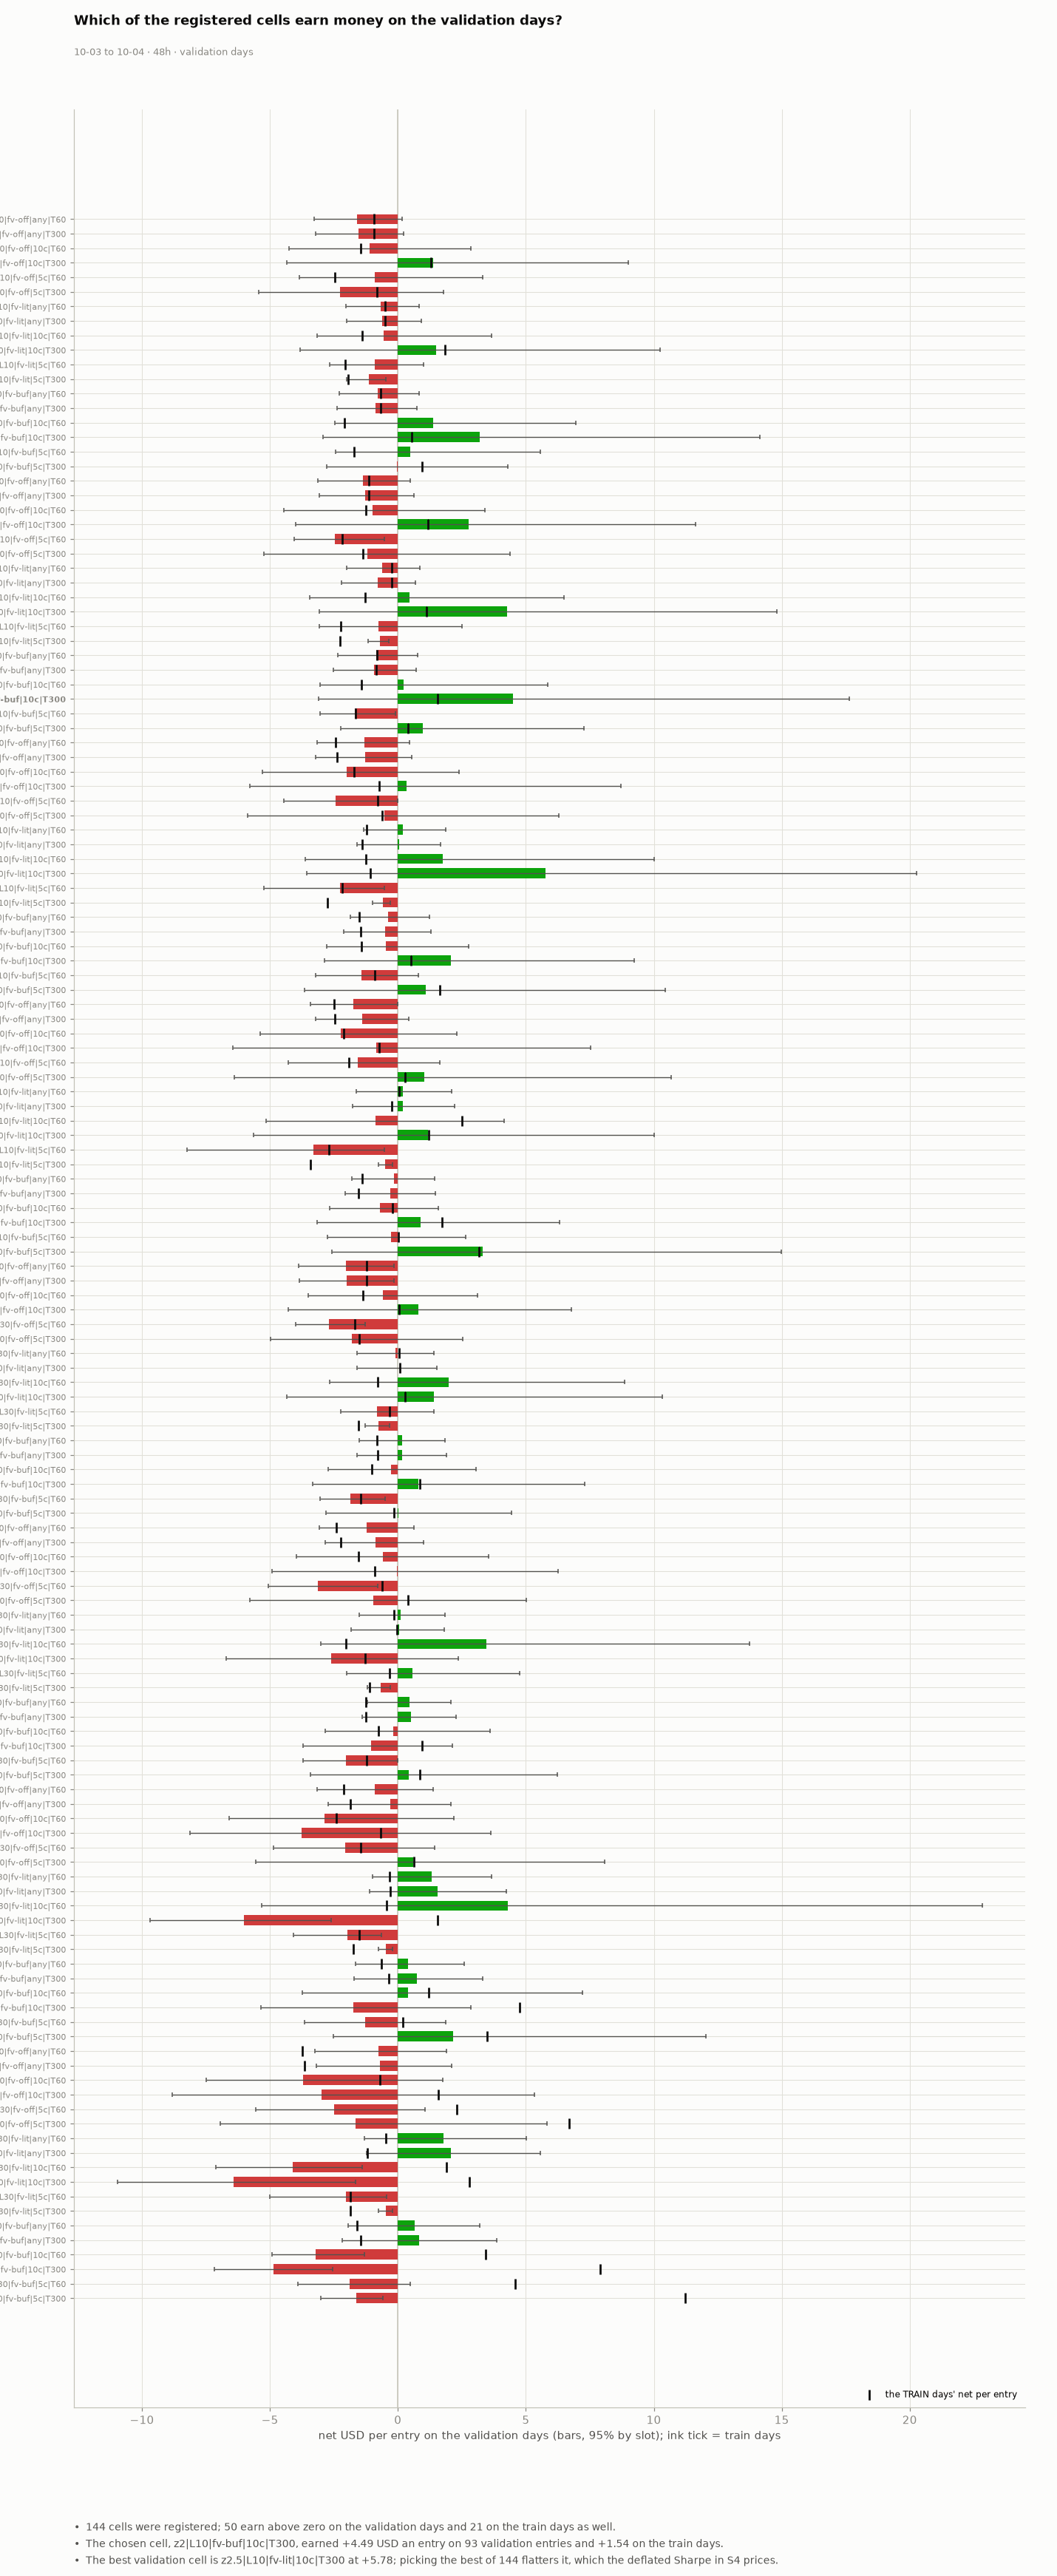

In [8]:
# ---- the grid on the validation days (every registered cell), fig:s3-grid ----
_rows = []
for c_ in CELLS:
    tr_, va_ = c_["train"], c_["validate"]
    _rows.append({"cell": c_["cfg"]["name"], "train n": tr_.get("n", 0), "train per": tr_.get("per", np.nan), "valid n": va_.get("n", 0), "valid per": va_.get("per", np.nan), "valid lo": va_.get("per_lo", np.nan),
                  "valid hi": va_.get("per_hi", np.nan), "valid win %": va_.get("win", np.nan) * 100, "valid be %": va_.get("breakeven", np.nan) * 100})
GRID = pd.DataFrame(_rows)
_best = GRID.sort_values("valid per", ascending=False).iloc[0]
_bul = [f"{len(GRID)} cells were registered; {int((GRID['valid per'] > 0).sum())} earn above zero on the validation days and {int(((GRID['valid per'] > 0) & (GRID['train per'] > 0)).sum())} on the train days as well.",
        f"The chosen cell, {CHOSEN['name']}, earned {sgn(GRID.set_index('cell').loc[CHOSEN['name'], 'valid per'])} USD an entry on {int(GRID.set_index('cell').loc[CHOSEN['name'], 'valid n'])} validation entries and {sgn(GRID.set_index('cell').loc[CHOSEN['name'], 'train per'])} on the train days."
        + ("" if RES["qualified"] else " No cell was positive on both, so the best validation cell is read on the test days as a miss by construction."),
        f"The best validation cell is {_best['cell']} at {sgn(_best['valid per'])}; picking the best of {len(GRID)} flatters it, which the deflated Sharpe in S4 prices."]
fig = FIGS.grid_fig(CELLS, CHOSEN, WIN_VAL, _bul, "Which of the registered cells earn money on the validation days?")
figstyle.show(fig, "fig:s3-grid", FIGURES)

In [9]:
# ---- the test days, read once for the chosen cell ----
_d = RP.by_day(ENT, TABS["test"])
display(Markdown(f"**Chosen cell {CHOSEN['name']}, test days {TEST_DAYS[0]} to {TEST_DAYS[-1]}.** {TS['n']} entries; win rate {pct(TS['win'])} (Wilson {pct(TS['win_lo'])} to {pct(TS['win_hi'])}) against {pct(TS['breakeven'])} needed to break even (price plus fee); "
                 f"net {sgn(TS['net'], 0)} USD, {sgn(TS['per'])} an entry (95% by 15-minute slot {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}); before costs {sgn(TS['gross_per'])} an entry, costs {TS['fee_per']:.2f}."))
display(HTML(_d.round(3).to_html(border=0)))
TEST_FRAME = RP.frame(ENT, TABS["test"])

**Chosen cell z2|L10|fv-buf|10c|T300, test days 2026-10-05 to 2026-10-06.** 176 entries; win rate 7.4% (Wilson 4.4% to 12.2%) against 5.9% needed to break even (price plus fee); net +240 USD, +1.37 an entry (95% by 15-minute slot -2.70 to +6.66); before costs +1.70 an entry, costs 0.33.

,entries,win,vwap,net,per,gross_per,fee_per
date,,,,,,,
2026-10-05,86.0,0.058,0.055,88.412,1.028,1.432,0.404
2026-10-06,90.0,0.089,0.055,152.079,1.690,1.954,0.264


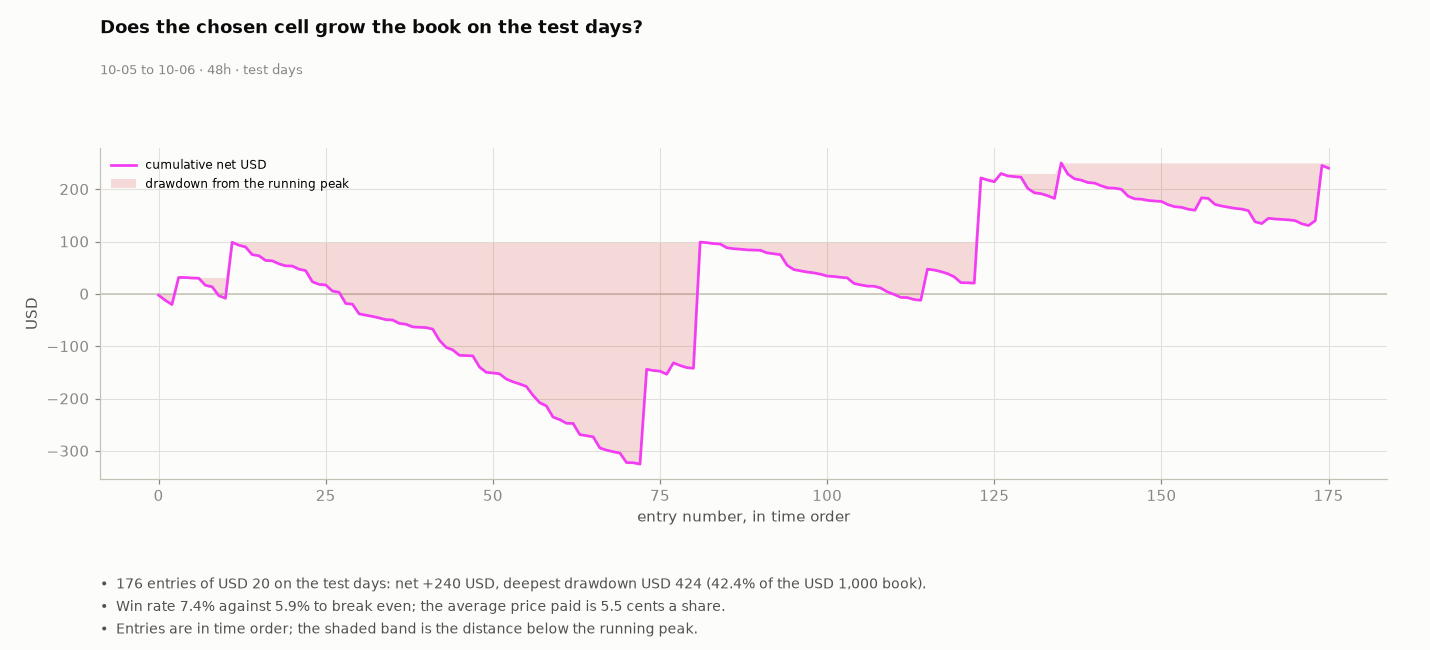

In [10]:
_s, _eq, _dd, _ddpath = RP.equity(ENT, TABS["test"])
_bul = [f"{TS['n']} entries of USD {CLIP_USD:g} on the test days: net {sgn(TS['net'], 0)} USD, deepest drawdown {usd(_dd)} ({_dd / BOOK_USD * 100:.1f}% of the USD {BOOK_USD:,.0f} book).",
        f"Win rate {pct(TS['win'])} against {pct(TS['breakeven'])} to break even; the average price paid is {TS['vwap'] * 100:.1f} cents a share.",
        "Entries are in time order; the shaded band is the distance below the running peak."]
fig = FIGS.equity_fig(_eq, _ddpath, WIN_TEST, _bul, "Does the chosen cell grow the book on the test days?")
figstyle.show(fig, "fig:s3-equity", FIGURES)

## S4 · Robustness

| question | gate to S6 |
|---|---|
| Is it real: does the placebo earn as much, does a planted peek pay far more, does it survive the delay, twice the fee, both test days, and the number of cells tried? | the rows of the gate table below |

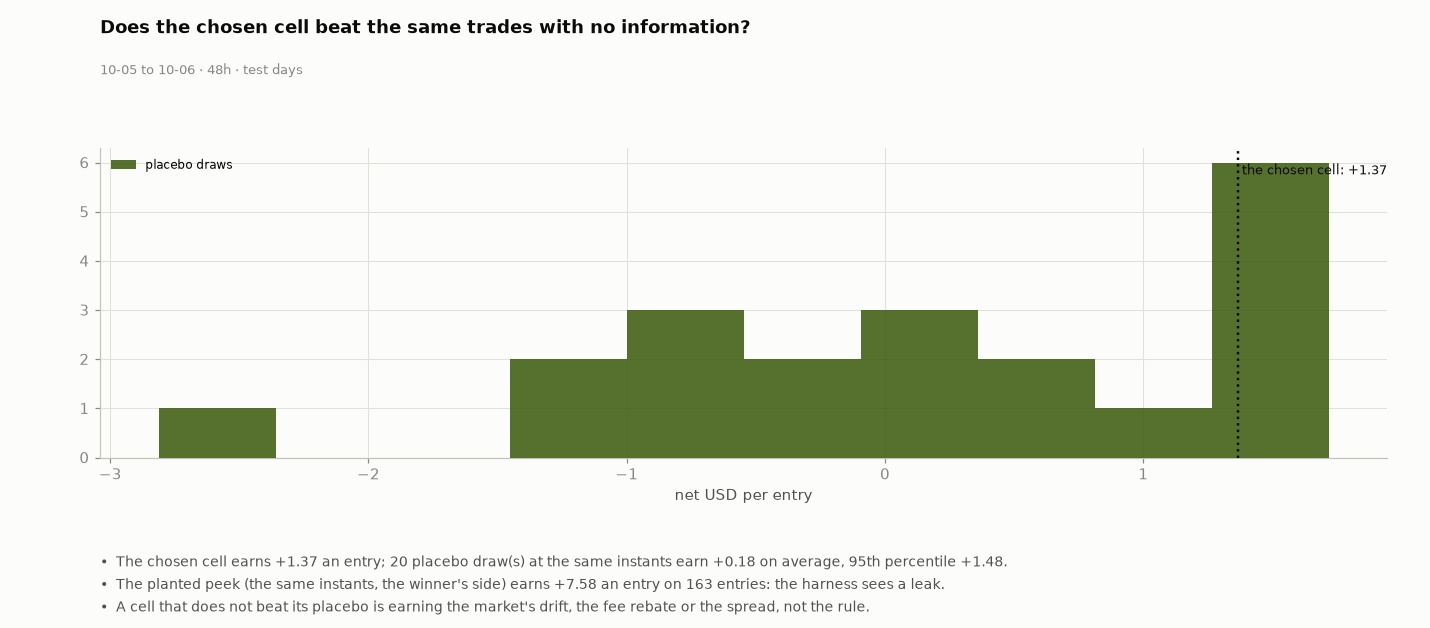

In [11]:
# ---- placebo and planted peek (the harness would see a leak) ----
PL = RES["placebo"]
PK = RES["peek"]
_pl = np.array([p_["per"] for p_ in PL if p_.get("n", 0) > 0]) if PL else np.array([])
_ref = float(np.quantile(_pl, 0.95)) if len(_pl) > 1 else (float(_pl[0]) if len(_pl) else float("inf"))
_bul = [(f"The chosen cell earns {sgn(TS['per'])} an entry; {len(_pl)} placebo draw(s) at the same instants earn {sgn(float(_pl.mean()))} on average, 95th percentile {sgn(_ref)}." if len(_pl) else "No placebo ran."),
        (f"The planted peek (the same instants, the winner's side) earns {sgn(PK['per'])} an entry on {PK['n']} entries: the harness sees a leak." if PK else "No planted peek ran."),
        "A cell that does not beat its placebo is earning the market's drift, the fee rebate or the spread, not the rule."]
fig = FIGS.placebo_fig(TS["per"], _pl, WIN_TEST, _bul, "Does the chosen cell beat the same trades with no information?")
figstyle.show(fig, "fig:s4-placebo", FIGURES)

delay table in 2s


delay_ms,n,win,per,lo,hi,net
0,171,0.076,-0.298,-3.662,4.080,-50.911
50,172,0.076,0.426,-3.290,5.342,73.233
150,176,0.074,1.366,-2.697,6.661,240.491
250,177,0.073,1.247,-3.118,6.950,220.637
500,178,0.079,1.063,-3.397,6.879,189.206


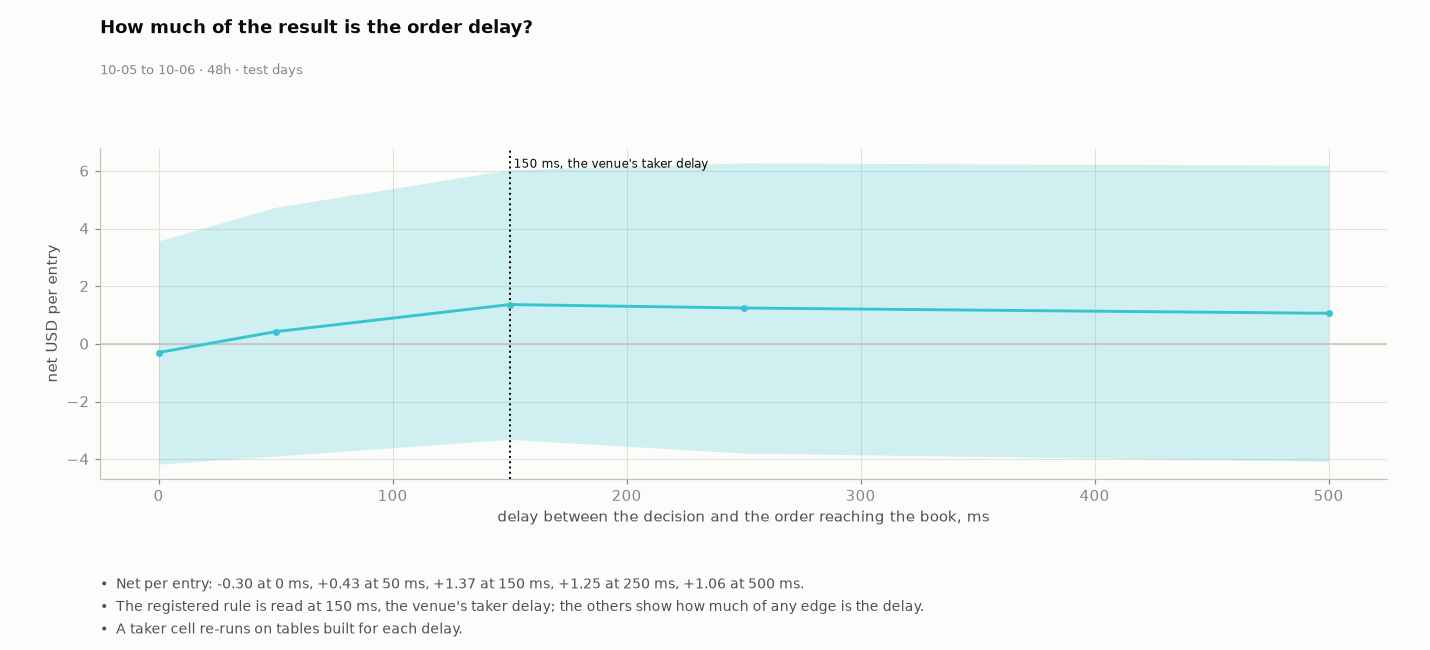

In [12]:
# ---- the delay: a taker cell re-run on tables built for each order delay; a resting cell with its post and cancel latencies moved ----
t0 = time.time()
DELAY = RP.delay_table(CAND, CHOSEN, RES["ctx"], TEST_DAYS, delays=(0, 50, 150, 250, 500))
print(f"delay table in {time.time() - t0:.0f}s")
display(HTML(DELAY.round(3).to_html(index=False, border=0)))
_d150 = DELAY.set_index("delay_ms")
_bul = [f"Net per entry: {', '.join(f'{sgn(r_.per)} at {int(r_.delay_ms)} ms' for r_ in DELAY.itertuples())}.",
        "The registered rule is read at 150 ms, the venue's taker delay; the others show how much of any edge is the delay.",
        ("A taker cell re-runs on tables built for each delay." if CAND.family == "taker" else "A resting cell moves its post and cancel latencies together.")]
fig = FIGS.delay_fig(DELAY, WIN_TEST, _bul, "How much of the result is the order delay?")
figstyle.show(fig, "fig:s4-delay", FIGURES)

In [13]:
# ---- costs ----
COST = RP.cost_table(CAND, CHOSEN, RES["ctx"], TABS["test"])
display(HTML(COST.round(3).to_html(index=False, border=0)))

case,n,win,per,lo,hi,net
as registered,176,0.074,1.366,-2.697,6.661,240.491
fee x2,176,0.074,1.034,-3.031,6.345,181.946
a cent worse on every fill,176,0.074,0.442,-3.600,5.755,77.827
clip USD 5,176,0.074,0.158,-1.643,2.276,27.807
clip USD 100,176,0.074,6.827,-4.670,23.744,1201.560


In [14]:
# ---- by day, and the deflated Sharpe for the number of cells tried ----
_bd = RP.by_day(ENT, TABS["test"])
_pos_days = int((_bd["net"] > 0).sum())
DSR = RES["dsr"]
SH = RES["test_sharpe"]
_slot_sh = B.slot_sharpe(ENT, TABS["test"]) if TS["n"] else float("nan")
_daily_sh = TS.get("sharpe_daily", float("nan"))
display(Markdown(f"**Sharpe.** Per entry (mean over standard deviation) {SH['sr']:+.3f} on {SH['n']} entries (skew {SH['skew']:+.1f}, kurtosis {SH['kurt']:.1f}); annualised on 15-minute slots {sgn(_slot_sh, 1)}, on days {sgn(_daily_sh, 1)} (two days: a rough label only). "
                 f"The best of {N_TRIALS} cells is deflated against the spread of the cells' own Sharpe ratios: SR0 {DSR['sr0']:+.3f}, probabilistic {DSR['psr']:.2f}, **deflated {DSR['dsr']:.2f}**." if SH and DSR else "Too few entries for a Sharpe."))

**Sharpe.** Per entry (mean over standard deviation) +0.043 on 176 entries (skew +5.4, kurtosis 35.0); annualised on 15-minute slots +7.7, on days +51.0 (two days: a rough label only). The best of 144 cells is deflated against the spread of the cells' own Sharpe ratios: SR0 +0.835, probabilistic 0.74, **deflated 0.00**.

In [15]:
# ---- days outside the registered split, read AFTER the test days for the cell already chosen (informational, outside the decision rule): an earlier week and a fresh forward day ----
XR = {}
for lab_, days_all_ in EXTRA_DAYS.items():
    days_ = [d_ for d_ in days_all_ if RUNNER.seated(d_) is not None]
    if len(days_) < len(days_all_):
        print(f"{lab_}: {len(days_all_) - len(days_)} of {len(days_all_)} days are not seated and are left out: {sorted(set(days_all_) - set(days_))}")
    if not days_:
        continue
    try:
        tx_ = B.Tab(days_)
        xe_ = CAND.run(tx_, CHOSEN, RES["ctx"])
        XR[lab_] = (tx_, xe_, B.summarize(xe_, tx_, lab_))
    except LookupError as e_:
        print(f"{lab_}: not seated ({str(e_)[:100]})")
_rows = [dict(block="registered test days", days=f"{TEST_DAYS[0][5:]} to {TEST_DAYS[-1][5:]}", n=TS["n"], win=TS["win"], breakeven=TS["breakeven"], net=TS["net"], per=TS["per"], lo=TS["per_lo"], hi=TS["per_hi"])]
for lab_, (tx_, xe_, sx_) in XR.items():
    if sx_.get("n", 0):
        _rows.append(dict(block=lab_, days=f"{tx_.days[0][5:]} to {tx_.days[-1][5:]}", n=sx_["n"], win=sx_["win"], breakeven=sx_["breakeven"], net=sx_["net"], per=sx_["per"], lo=sx_["per_lo"], hi=sx_["per_hi"]))
POOL = RP.pool([ENT] + [xe_ for (_, xe_, _) in XR.values()])
SP = B.summarize(POOL)
if SP.get("n", 0):
    _rows.append(dict(block="pooled, all days outside train and validation", days="", n=SP["n"], win=SP["win"], breakeven=SP["breakeven"], net=SP["net"], per=SP["per"], lo=SP["per_lo"], hi=SP["per_hi"]))
XT = pd.DataFrame(_rows)
display(Markdown("**The chosen cell on the days outside the registered split** (read after the test days; none was used to choose it; the earlier week is before the train days, the fresh day after the test days)"))
display(HTML(XT.round(3).to_html(index=False, border=0)))
FRESH = XR.get("fresh day", (None, None, None))[2]
WEEK = XR.get("earlier week", (None, None, None))[2]
GATES.append({"id": "G11", "section": "S4", "label": "Other days, for record", "name": "the chosen cell on an earlier week and a fresh day nobody had read when it was chosen; informational, outside the decision rule",
              "reading": (f"earlier week {sgn(WEEK['per'])} on {WEEK['n']}; fresh day {sgn(FRESH['per'])} on {FRESH['n']}" if WEEK and FRESH and WEEK.get("n", 0) and FRESH.get("n", 0) else (f"earlier week {sgn(WEEK['per'])} on {WEEK['n']}" if WEEK and WEEK.get("n", 0) else "no other day read")),
              "verdict": "INFO", "would_change": "a result on more days"})
GATES.append({"id": "G12", "section": "S4", "label": "Pooled out of sample", "name": "net per entry over every day outside the train and validation days, with a 95% interval over 15-minute slots; informational: the decision rule reads the registered test days",
              "reading": (f"{sgn(SP['per'])} USD an entry on {SP['n']} entries, 95% {sgn(SP['per_lo'])} to {sgn(SP['per_hi'])}" if SP.get("n", 0) else "no entry"), "verdict": "INFO", "would_change": "more days"})

**The chosen cell on the days outside the registered split** (read after the test days; none was used to choose it; the earlier week is before the train days, the fresh day after the test days)

block,days,n,win,breakeven,net,per,lo,hi
registered test days,10-05 to 10-06,176,0.074,0.059,240.491,1.366,-2.697,6.661
earlier week,09-23 to 09-29,518,0.066,0.059,5.561,0.011,-1.966,2.403
fresh day,10-07 to 10-07,81,0.037,0.059,-215.787,-2.664,-6.792,3.348
"pooled, all days outside train and validation",,775,0.065,0.059,30.265,0.039,-1.814,2.170


## S5 · Risk and diagnostics

| question | answer form |
|---|---|
| Where does the money, or the loss, come from: coin, price paid, time left, day? | tables and one figure |

**By coin**

,entries,win,vwap,net,per,gross_per,fee_per
coin,,,,,,,
btc,29.0,0.103,0.048,278.090,9.589,10.450,0.861
eth,49.0,0.061,0.059,-130.379,-2.661,-2.310,0.350
sol,48.0,0.083,0.067,159.086,3.314,3.506,0.192
xrp,50.0,0.060,0.059,-66.305,-1.326,-1.182,0.144


**By time left**

,entries,win,vwap,net,per,gross_per,fee_per
left,,,,,,,
"[300, 600)",137.0,0.080,0.054,351.985,2.569,2.892,0.322
"[600, 901)",39.0,0.051,0.059,-111.494,-2.859,-2.490,0.369


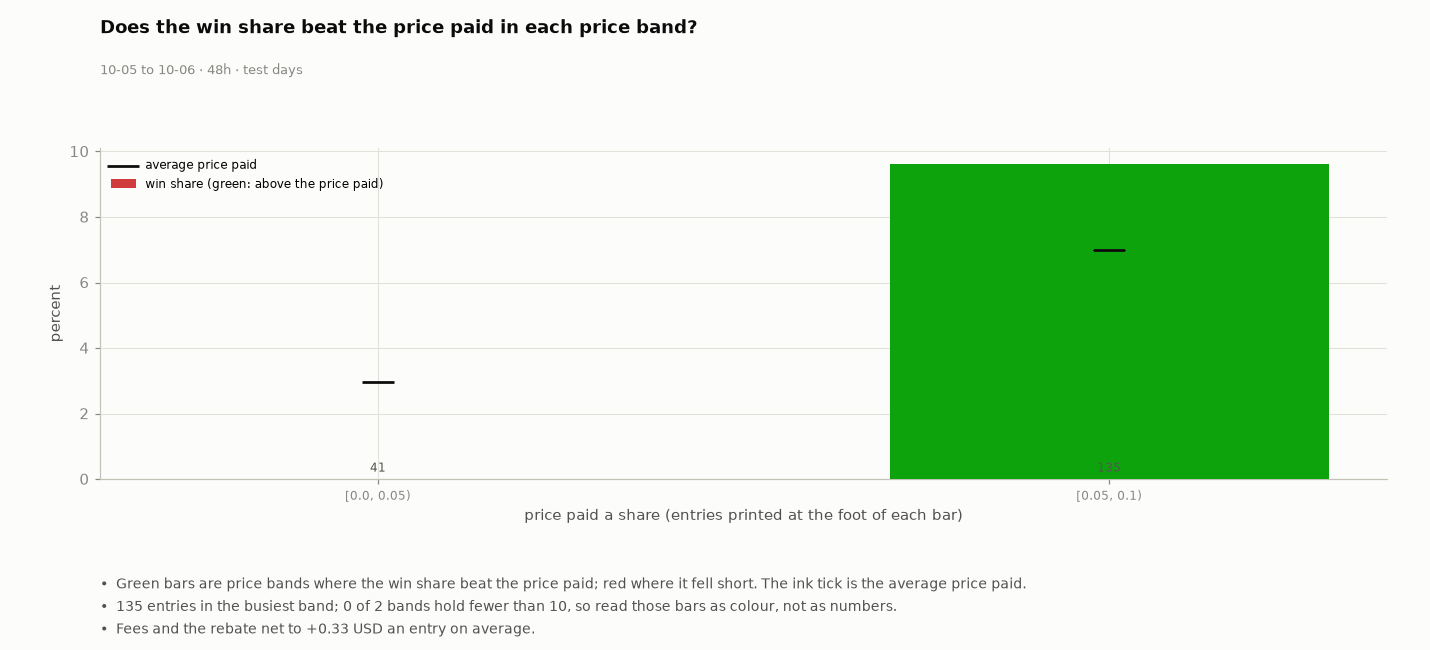

In [16]:
_ba = RP.by_asset(ENT, TABS["test"])
_bb = RP.by_band(ENT, TABS["test"])
_bl = RP.by_left(ENT, TABS["test"])
display(Markdown("**By coin**")); display(HTML(_ba.round(3).to_html(border=0)))
display(Markdown("**By time left**")); display(HTML(_bl.round(3).to_html(border=0)))
_bul = ["Green bars are price bands where the win share beat the price paid; red where it fell short. The ink tick is the average price paid.",
        f"{int(_bb['entries'].max())} entries in the busiest band; {int((_bb['entries'] < 10).sum())} of {len(_bb)} bands hold fewer than 10, so read those bars as colour, not as numbers.",
        f"Fees and the rebate net to {sgn(TS['fee_per'])} USD an entry on average."]
fig = FIGS.band_fig(_bb, WIN_TEST, _bul, "Does the win share beat the price paid in each price band?")
figstyle.show(fig, "fig:s5-price", FIGURES)

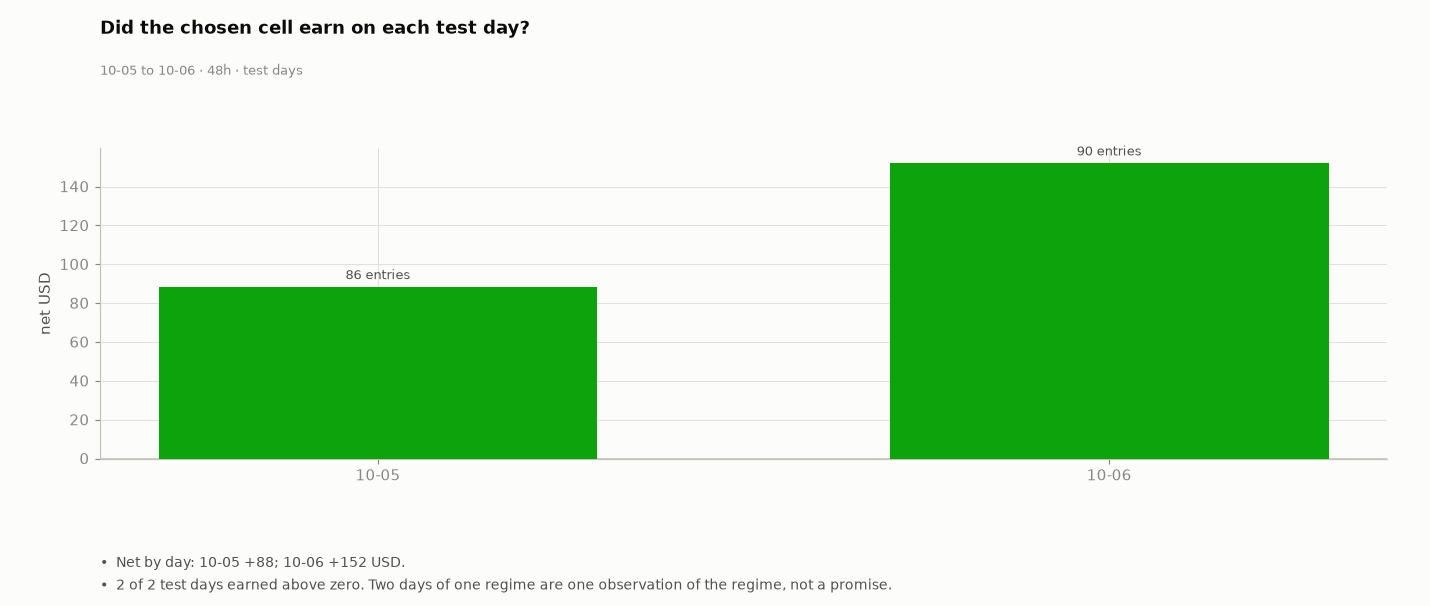

In [17]:
fig = FIGS.daily_fig(_bd, WIN_TEST, [f"Net by day: " + "; ".join(f"{d_[5:]} {sgn(r_.net, 0)}" for d_, r_ in _bd.iterrows()) + " USD.",
                                       f"{_pos_days} of {len(_bd)} test days earned above zero. Two days of one regime are one observation of the regime, not a promise."], "Did the chosen cell earn on each test day?")
figstyle.show(fig, "fig:s5-daily", FIGURES)

## S6 · Decision

| question | decision rule |
|---|---|
| If it passed: what size, can it be filled, what are the limits? | a size only if every gate below passed (`SIZED`); else the rung prints as information only |

In [18]:
SZ = RP.sizing(ENT, TABS["test"], CLIP_USD)
display(Markdown(f"**Sizing read (information unless every gate passes).** {SZ['per_day']:.0f} fills a day of USD {CLIP_USD:g} (median fill USD {SZ['median_fill_usd']:.1f}), USD {SZ['cost_per_day']:,.0f} deployed a day, net {sgn(SZ['net_per_day'], 0)} USD a day on a USD {BOOK_USD:,.0f} book "
                 f"({sgn(SZ['ret_pct_of_book_per_day'], 1)}% a day), deepest drawdown {usd(SZ['max_dd_usd'])} ({SZ['dd_pct_of_book']:.1f}% of the book). Capacity is the visible depth: a clip of USD 100 changes the fill, see the cost table."))
# ---- the gates, as data ----
def gate(i, label, name, reading, ok, would):
    GATES.append({"id": i, "section": "S4", "label": label, "name": name, "reading": reading, "verdict": "PASS" if ok else "FAIL", "would_change": would})
_lo, _per = TS["per_lo"], TS["per"]
gate("G2", "Net per entry above 0", "the chosen cell's test net per entry is above zero with a 95% interval above zero", f"{sgn(_per)} USD an entry, 95% {sgn(_lo)} to {sgn(TS['per_hi'])}, on {TS['n']} entries", _lo > 0 and _per > 0, "an interval that includes zero")
_pl_ok = bool(len(_pl)) and TS["per"] > _ref
gate("G3", "Beats the placebo", "the cell earns more per entry than the placebo's 95th percentile (or the single blind placebo)", f"{sgn(TS['per'])} against {sgn(_ref)}", _pl_ok, "a placebo that earns as much")
_pk_ok = bool(PK) and PK["n"] > 0 and PK["per"] > max(TS["per"], 0) + 1.0
VERIFY["total"] += 1
VERIFY["passed"] += int(_pk_ok)
gate("G4", "Planted peek caught", "a planted look at the outcome pays far more than the cell", f"peek {sgn(PK['per']) if PK else 'n/a'} against {sgn(TS['per'])}", _pk_ok, "a harness that cannot tell a leak")
_d = DELAY.set_index("delay_ms")
_dok = bool(_d.loc[150, "per"] > 0 and _d.loc[250, "per"] > 0)
gate("G5", "Survives 150 and 250 ms", "net per entry stays above zero at the venue's delay and at 250 ms", f"{sgn(_d.loc[150, 'per'])} at 150 ms, {sgn(_d.loc[250, 'per'])} at 250 ms; {sgn(_d.loc[0, 'per'])} with no delay", _dok, "an edge that lives inside the delay")
_c = COST.set_index("case")
_cname = "fee x2" if CAND.family == "taker" else "no maker rebate"
gate("G6", "Survives costlier fills", "net per entry stays above zero at twice the fee (a resting order: with no rebate)", f"{sgn(_c.loc[_cname, 'per'])} at {_cname}", bool(_c.loc[_cname, "per"] > 0), "a cell whose edge is smaller than a fee")
gate("G7", "Positive on both days", "the net is above zero on every test day", f"{_pos_days} of {len(_bd)} test days above zero", bool(_pos_days == len(_bd) and len(_bd) > 0), "a result carried by one day")
gate("G8", "Chosen on both sides", "the chosen cell is positive on the train days as well as the validation days", f"qualified {RES['qualified']}", bool(RES["qualified"]), "a cell positive on one window only")
gate("G9", "Deflated Sharpe", "the deflated Sharpe, which charges for the number of cells tried, is at least 0.90", f"deflated {DSR['dsr']:.2f}, {N_TRIALS} cells" if DSR and DSR["dsr"] == DSR["dsr"] else "not computable", bool(DSR and DSR["dsr"] == DSR["dsr"] and DSR["dsr"] >= 0.9), "a Sharpe within the luck of the best of N")
_core = ("G1", "G2", "G3", "G4", "G5", "G6", "G7")
GV_ = {g_["id"]: g_["verdict"] for g_ in GATES}
SIZED = all(GV_[i_] == "PASS" for i_ in _core)
WORD = "1x" if SIZED else "NO SIZE"
CLASS = "A" if SIZED else ("B" if TS["per"] > 0 else "C")
CLASS_TXT = {"A": "money: every gate passed", "B": "a positive point estimate that the interval, the placebo or the delay does not support", "C": "no money"}[CLASS]
display(Markdown(f"**Decision: {'a USD 20 clip, one position per window, paper only' if SIZED else 'NO SIZE'}.** " + ("Every gate of the rule passed." if SIZED else f"Not passed: {', '.join(g_['label'] for g_ in GATES if g_['verdict'] == 'FAIL' and g_['id'] in _core)}. The rung is information only.")))
GATES.append({"id": "G10", "section": "S6", "label": "Sized only if passed", "name": "the decision rule reads G1 to G7: a size only when all pass, else the rung is information only", "reading": f"{'SIZED' if SIZED else 'NO SIZE'}: {sgn(TS['per'])} USD an entry",
              "verdict": "PASS" if SIZED else "FAIL", "would_change": "any gate it reads"})

**Sizing read (information unless every gate passes).** 88 fills a day of USD 20 (median fill USD 2.9), USD 447 deployed a day, net +120 USD a day on a USD 1,000 book (+12.0% a day), deepest drawdown USD 424 (42.4% of the book). Capacity is the visible depth: a clip of USD 100 changes the fill, see the cost table.

**Decision: NO SIZE.** Not passed: Net per entry above 0, Beats the placebo. The rung is information only.

## S7 · Verdict

In [19]:
# ---- the plain-words answer, from the run's own numbers ----
HEADLINE_MD = (f"**The answer: {'MONEY' if SIZED else 'NO MONEY'}, class {CLASS}.** The chosen cell, {CHOSEN['name']}, earned {sgn(TS['per'])} USD an entry on {TS['n']} test entries "
               f"(95% by slot {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}), {sgn(TS['net'], 0)} USD net after costs. It won {pct(TS['win'])} of its entries against {pct(TS['breakeven'])} needed to break even. "
               f"Sharpe per entry {SH['sr']:+.3f}, deflated {DSR['dsr']:.2f} over {N_TRIALS} cells. At no delay it earns {sgn(_d.loc[0, 'per'])}, at 150 ms {sgn(_d.loc[150, 'per'])}, at 250 ms {sgn(_d.loc[250, 'per'])}. "
               f"{'The placebo is beaten and the planted peek is caught.' if (_pl_ok and _pk_ok) else 'It does not clear the placebo or the planted-peek test.'} " + "A tail pays rarely, so a few hundred entries cannot tell a mispriced tail from luck: read the interval, not the point.")
display(Markdown(HEADLINE_MD))

**The answer: NO MONEY, class B.** The chosen cell, z2|L10|fv-buf|10c|T300, earned +1.37 USD an entry on 176 test entries (95% by slot -2.70 to +6.66), +240 USD net after costs. It won 7.4% of its entries against 5.9% needed to break even. Sharpe per entry +0.043, deflated 0.00 over 144 cells. At no delay it earns -0.30, at 150 ms +1.37, at 250 ms +1.25. It does not clear the placebo or the planted-peek test. A tail pays rarely, so a few hundred entries cannot tell a mispriced tail from luck: read the interval, not the point.

In [20]:
for g_ in GATES:
    assert g_["verdict"] in REPORT.GATE_VERDICTS, g_
    assert len(g_["label"]) <= REPORT.MAX_GATE_LABEL, (g_["label"], len(g_["label"]))
assert len({g_["id"] for g_ in GATES}) == len(GATES)
GATES.sort(key=lambda g_: int(g_["id"][1:]))
GV = {g_["id"]: g_["verdict"] for g_ in GATES}
display(Markdown("**Gates**\n\n| Id | Section | Gate | Reading | Verdict |\n|---|---|---|---|---|\n" + "\n".join(f"| {g_['id']} | {g_['section']} | {g_['label']} | {g_['reading']} | **{g_['verdict']}** |" for g_ in GATES)))
RESULT_LINES = [f"RESULT um-010 test_entries={TS['n']}", f"RESULT um-010 test_win_rate_pct={TS['win'] * 100:.2f}", f"RESULT um-010 test_net_per_entry_usd={TS['per']:.4f}",
                f"RESULT um-010 test_net_pnl_usd={TS['net']:.2f}", f"RESULT um-010 test_sharpe_per_entry={SH['sr']:.4f}", f"RESULT um-010 deflated_sharpe={DSR['dsr']:.3f}"]
print("\n".join(RESULT_LINES))

**Gates**

| Id | Section | Gate | Reading | Verdict |
|---|---|---|---|---|
| G1 | S2 | Windows have a book | 94.2% of 2688 windows | **PASS** |
| G2 | S4 | Net per entry above 0 | +1.37 USD an entry, 95% -2.70 to +6.66, on 176 entries | **FAIL** |
| G3 | S4 | Beats the placebo | +1.37 against +1.48 | **FAIL** |
| G4 | S4 | Planted peek caught | peek +7.58 against +1.37 | **PASS** |
| G5 | S4 | Survives 150 and 250 ms | +1.37 at 150 ms, +1.25 at 250 ms; -0.30 with no delay | **PASS** |
| G6 | S4 | Survives costlier fills | +1.03 at fee x2 | **PASS** |
| G7 | S4 | Positive on both days | 2 of 2 test days above zero | **PASS** |
| G8 | S4 | Chosen on both sides | qualified True | **PASS** |
| G9 | S4 | Deflated Sharpe | deflated 0.00, 144 cells | **FAIL** |
| G10 | S6 | Sized only if passed | NO SIZE: +1.37 USD an entry | **FAIL** |
| G11 | S4 | Other days, for record | earlier week +0.01 on 518; fresh day -2.66 on 81 | **INFO** |
| G12 | S4 | Pooled out of sample | +0.04 USD an entry on 775 entries, 95% -1.81 to +2.17 | **INFO** |

RESULT um-010 test_entries=176
RESULT um-010 test_win_rate_pct=7.39
RESULT um-010 test_net_per_entry_usd=1.3664
RESULT um-010 test_net_pnl_usd=240.49
RESULT um-010 test_sharpe_per_entry=0.0431
RESULT um-010 deflated_sharpe=0.000


In [21]:
# ---- the card, the verdict and the manifest ----
_cut = lambda s, n: s if len(s) <= n else s[: n - 1].rstrip() + "."
mk = lambda metric, value, bar="", verdict="", gate=None: {"metric": metric, "value": value, "bar": bar, "verdict": GV[gate] if gate else verdict, **({"gate": gate} if gate else {})}
_wins, _loss = ENT["net"][ENT["net"] > 0], ENT["net"][ENT["net"] <= 0]
PF = float(_wins.sum() / abs(_loss.sum())) if len(_loss) and _loss.sum() != 0 else None
WLR = float(_wins.mean() / abs(_loss.mean())) if len(_wins) and len(_loss) else None
_dly = _bd["net"].to_numpy(float)
_hold_h = float(np.mean(ENT["T"]) / 3600.0) if TS["n"] else None
METRICS = {"ann_return_pct": None, "excess_vs_hurdle_pct": None, "ann_vol_pct": None, "sharpe": (None if _slot_sh != _slot_sh else float(_slot_sh)), "sortino": None, "calmar": None, "psr": float(DSR["psr"]), "dsr": float(DSR["dsr"]),
           "max_dd_pct": SZ["dd_pct_of_book"], "max_dd_days": float(len(TEST_DAYS)), "n_periods": float(len(TEST_DAYS) * 96), "periods_per_year": 96.0 * 365.0,
           "total_return_pct": TS["net"] / BOOK_USD * 100, "n_trades": float(TS["n"]), "trades_per_day": TS["n"] / len(TEST_DAYS), "hit_rate_pct": TS["win"] * 100,
           "profit_factor": PF, "expectancy_bps": TS["per"] / CLIP_USD * 1e4, "win_loss_ratio": WLR, "avg_hold_h": _hold_h, "exposure_pct": None,
           "turnover_ann": float(ENT["cost"].sum() / len(TEST_DAYS) * 365 / BOOK_USD), "fees_pct_of_gross": (float(ENT["fee"].sum() / abs(ENT["gross"].sum()) * 100) if ENT["gross"].sum() else None),
           "worst_period_pct": float(_dly.min() / BOOK_USD * 100), "gross_edge_bps": TS["gross_per"] / CLIP_USD * 1e4, "cost_bps": TS["fee_per"] / CLIP_USD * 1e4,
           "breakeven_cost_bps": TS["gross_per"] / CLIP_USD * 1e4, "capacity_usd": None, "beta_to_underlying": None}
NA = {"ann_return_pct": "two test days: an annualised return is not meaningful", "excess_vs_hurdle_pct": "two test days: an annualised excess is not meaningful", "ann_vol_pct": "two test days: an annualised volatility is not meaningful",
      "sortino": "two test days: not meaningful", "calmar": "two test days: not meaningful", "exposure_pct": "exposure over the window was not tracked per second", "capacity_usd": "the ladder depth beyond four levels is not kept",
      "beta_to_underlying": "a binary payoff on Up or Down: no single underlying beta"}
for k_, v_ in list(METRICS.items()):
    if v_ is None or (isinstance(v_, float) and not math.isfinite(v_)):
        METRICS[k_] = None
        NA.setdefault(k_, "no loss or no entry on the test days")
VERDICT = {"word": WORD, "why": [_cut(f"net {sgn(TS['per'])} USD per entry on {TS['n']} test entries, 95% by slot {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}", 110),
                                 _cut(f"win {pct(TS['win'])} against {pct(TS['breakeven'])} to break even; deflated Sharpe {DSR['dsr']:.2f} over {N_TRIALS} cells", 110),
                                 _cut(f"{sgn(_d.loc[150, 'per'])} per entry at 150 ms, {sgn(_d.loc[0, 'per'])} with no delay", 110)] if not SIZED else [_cut(f"every gate of the decision rule passed on {TS['n']} test entries", 110)],
           "next_bet": _cut("the same fade in the last minutes where the Binance average is nearly fixed, or a resting-bid version that earns the rebate instead of the taker fee", 150)}
CARD = {
    "question": _cut("Does fading a Binance momentum burst into the far tail earn a positive net PnL per entry after the fee and a 150 ms delay?", 200),
    "answer": _cut(f"{WORD}, class {CLASS}. {TS['n']} test entries net {sgn(TS['net'], 0)} USD ({sgn(TS['per'])} each, 95% {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}); win {pct(TS['win'])} vs {pct(TS['breakeven'])} to break even.", 220),
    "implementation": [("Trade", _cut("Buy the far tail a Binance burst left behind, at no worse than fair value", 70)), ("Venue", "Polymarket 15m crypto Up/Down; Binance is input"), ("Rule", _cut(CHOSEN["name"], 70)),
                      ("Size", f"{usd(CLIP_USD)} a trade, {usd(BOOK_USD)} book, 1x"), ("Costs", "taker fee 0.07 x p(1-p) or 20% maker rebate; +150 ms"), ("Window", f"{DAYS_ALL[0][5:]} to {DAYS_ALL[-1][5:]}, {HOURS_ALL}h, 1 regime")],
    "big": [dict(mk("Net per entry", f"{sgn(TS['per'])} USD", f"95% {sgn(TS['per_lo'])} to {sgn(TS['per_hi'])}", gate="G2"), scope="test"),
            dict(mk("Net after costs", f"{sgn(TS['net'], 0)} USD", f"{TS['n']} entries", gate="G2"), scope="test"),
            dict(mk("Win rate", pct(TS["win"]), f"break-even {pct(TS['breakeven'])}", verdict="INFO"), scope="test"),
            dict(mk("Deflated Sharpe", f"{DSR['dsr']:.2f}", "at least 0.90", gate="G9"), scope="test")],
    "blocks": [
        {"title": "Money", "rows": [mk("Net per entry", f"{sgn(TS['per'])} USD", "interval above 0", gate="G2"), mk("Before costs, per entry", f"{sgn(TS['gross_per'])} USD", "", "INFO"), mk("Costs, per entry", f"{TS['fee_per']:.2f} USD", "", "INFO"),
                                    mk("Sharpe per entry", f"{SH['sr']:+.3f}", "", "INFO"), mk("Sharpe, 15-minute slots", sgn(_slot_sh, 1), "", "INFO")]},
        {"title": "Is it real", "rows": [mk("Placebo, 95th percentile", sgn(_ref), "below the cell", gate="G3"), mk("Planted peek", sgn(PK["per"]) if PK else "n/a", "pays more", gate="G4"), mk("Days above zero", f"{_pos_days} of {len(_bd)}", "all", gate="G7"),
                                       mk("Positive on train days", "yes" if RES["qualified"] else "no", "yes", gate="G8"),
                                       mk("Pooled other days, per entry", sgn(SP["per"]) if SP.get("n", 0) else "n/a", "informational", gate="G12")]},
        {"title": "Delay and cost", "rows": [mk("No delay, per entry", sgn(_d.loc[0, "per"]), "", "INFO"), mk("150 ms, per entry", sgn(_d.loc[150, "per"]), "above 0", gate="G5"), mk("250 ms, per entry", sgn(_d.loc[250, "per"]), "above 0", gate="G5"),
                                  mk(_cname.capitalize() if CAND.family == "taker" else "No rebate", sgn(_c.loc[_cname, "per"]), "above 0", gate="G6")]},
        {"title": "Risk, USD", "rows": [mk("Deepest drawdown", sgn(-SZ["max_dd_usd"], 0), f"book {usd(BOOK_USD)}", "INFO"), mk("Worst day", sgn(float(_dly.min()), 0), "", "INFO"), mk("Fills a day", f"{SZ['per_day']:.0f}", "", "INFO"), mk("Net a day", sgn(SZ["net_per_day"], 0), "", "INFO")]},
        {"title": "Checks", "rows": [mk("Windows with a book", pct(SHARE, 0), "90% bar", gate="G1"), mk("Cells tried", f"{N_TRIALS}", "", "INFO"), mk("Engine checks held", f"{VERIFY['passed']} of {VERIFY['total']}", "all", "INFO")]}],
    "sizes": {"cols": ["Size", "Net, USD", "Per entry", "Verdict"], "chosen": 0 if SIZED else None, "rows": [["1x" if SIZED else "1x info only", sgn(TS["net"], 0), sgn(TS["per"], 2), "PASS" if SIZED else "FAIL"]]},
    "footer": [_cut(f"Registered as {RUN_ID} before the engine ran; {N_TRIALS} cells on the train and validation days, the test days read once.", 160),
               _cut("The Polymarket days are those of um-003 and um-004: one window, one regime, not an independent observation.", 160),
               _cut(f"{HOURS_ALL}h, {VERIFY['passed']}/{VERIFY['total']} checks; Binance and Polymarket clocks taken as one.", 160)]}
_probs = REPORT.card_problems(CARD, metrics={k_: (None if v_ is None else float(v_)) for k_, v_ in METRICS.items()}, gates={g_["id"]: g_ for g_ in GATES}, word=WORD, carry=False)
assert not _probs, _probs

In [22]:
# ---- the study manifest fund.study/1 (directional format, systematic style) ----
import hashlib
from fundplat.data.predmkts import updown15_pin
from fundplat.data import derived
from fundplat.data.crypto import ticks
STUDY_GATES = [{k_: g_[k_] for k_ in ("id", "section", "name", "label", "reading", "verdict", "would_change")} for g_ in GATES]
_series, _unpinned = [], []
_ms = lambda d_: int(dt.datetime.strptime(d_, "%Y-%m-%d").replace(tzinfo=dt.timezone.utc).timestamp() * 1000)
for d_ in dict.fromkeys(DAYS_ALL):
    key_ = RUNNER.key_of(d_)
    m_ = derived.meta(TT.DATASET, key_)
    _series.append(dict(spec=f"tf15:{d_}:decision-table:-", pin=m_["hash"], rows=int(COV.drop_duplicates("day").set_index("day").loc[d_, "with_book"]), first_ts=_ms(d_), last_ts=_ms(d_) + 86_399_999, handle=None, cls="pin", trunc=False))
    try:
        ip_ = updown15_pin.input_pin(d_)
        _series.append(dict(spec=f"polymarket:updown15 {d_}:l2-ladders:-", pin=hashlib.sha256(f"updown15-l2:{d_}:{ip_['digest']}".encode()).hexdigest(), rows=int(ip_["rows"]), first_ts=_ms(d_), last_ts=_ms(d_) + 86_399_999, handle=None, cls="pin", trunc=False))
    except KeyError as e_:
        _unpinned.append({"what": f"polymarket updown15 ladders {d_}", "why": f"the day is not finalized by the ladder job ({str(e_)[:60]})"})
for s_ in ("BTCUSDT", "ETHUSDT", "SOLUSDT", "XRPUSDT"):
    ip_ = ticks.input_pin(s_, _ms(DAYS_ALL[0]), _ms(DAYS_ALL[-1]) + 86_400_000)
    _series.append(dict(spec=f"binance:{s_}:aggTrades:-", pin=hashlib.sha256(f"binance:{s_}:{ip_['digest']}".encode()).hexdigest(), rows=int(sum(f["rows"] for f in ip_["files"])), first_ts=_ms(DAYS_ALL[0]), last_ts=_ms(DAYS_ALL[-1]) + 86_399_999, handle=None, cls="pin", trunc=False))
_unpinned.append({"what": "gamma market list (updown15.markets)", "why": "a day cache of the venue's own listing, re-readable; its outcomes are inside the derived days' pins"})
if XR:
    _unpinned.append({"what": "days outside the registered split: " + ", ".join(f"{k_} {v_[0].days[0]} to {v_[0].days[-1]}" for k_, v_ in XR.items()), "why": "read after the registered test days for the record; not part of the registered inputs digest"})
INPUTS = {"digest": REPORT.inputs_digest([x_["pin"] for x_ in _series]), "series": _series, "unpinned": _unpinned}
PROFILE = {"market": "predmkts", "markets": ["predmkts", "crypto"], "venues": ["polymarket", "binance"], "instruments": ["BTC, ETH, SOL, XRP 15m Up/Down", "spot aggTrades"], "bar": "15m"}
COMPONENTS = [{"name": "PnL before costs", "usd": float(ENT["gross"].sum())}, {"name": "fees net of rebate", "usd": -float(ENT["fee"].sum())}]
assert abs(sum(c_["usd"] for c_ in COMPONENTS) - TS["net"]) < 0.01, "the PnL parts do not add to the net"
FIG_KINDS = {"fig:s3-grid": "parameter-surface", "fig:s3-equity": "equity-curve", "fig:s4-placebo": "significance-test", "fig:s4-delay": "signal-decay", "fig:s5-price": "calibration", "fig:s5-daily": "out-of-sample-test"}
assert {f_["id"] for f_ in FIGURES} == set(FIG_KINDS), set(FIG_KINDS) ^ {f_["id"] for f_ in FIGURES}
for f_ in FIGURES:
    f_["kind"] = FIG_KINDS[f_["id"]]
CAVEATS = ["two test days of one regime: one observation of the regime, not a promise",
           "the Polymarket days are those of um-003 and um-004: one window, not an independent observation",
           f"{N_TRIALS} cells tried on the train and validation days: the chosen cell's validation number is flattered",
           "the Binance trade-implied mid stands in for the Chainlink reference (about 1.9 bp apart, sd 0.8 bp)",
           "the book is a reconstruction of the venue's stream; Binance and Polymarket clocks taken as one",
           "a resting order joins the back of the queue and fills only from printed trades, with no cancels ahead",
           "the 150 ms taker delay is read from the venue changelog; no fact card carries it yet",
           "the first decision is 5 s after the start; thin markets (SOL, XRP) can have no book yet"]
assert all(len(c_) <= 110 for c_ in CAVEATS), [len(c_) for c_ in CAVEATS]
HEADLINE = {"metric": "net PnL per entry, USD, test days", "label": "Net per entry", "value": float(TS["per"]), "unit": "usd", "hurdle": 0.0, "gate": "G2"}
EQ = [(dt.datetime.fromtimestamp(_ms(TEST_DAYS[0]) / 1000, dt.timezone.utc) + dt.timedelta(minutes=15 * int(i_)), float(BOOK_USD + v_)) for i_, v_ in enumerate(_eq)] or [(dt.datetime.fromtimestamp(_ms(TEST_DAYS[0]) / 1000, dt.timezone.utc), BOOK_USD)]
STUDY = REPORT.build_manifest(
    id=STUDY_ID, kind=KIND, desk=DESK, title=TITLE, question=QUESTION, status="registered", run={"executed": RUN_AT, "kernel": "ccvenv"}, inputs=INPUTS, window=WINDOW,
    verify={"suite": VERIFY["suite"], "passed": VERIFY["passed"], "total": VERIFY["total"], "books": VERIFY["books"]}, gates=STUDY_GATES, figures=FIGURES, verdict=VERDICT, caveats=CAVEATS,
    headline=HEADLINE, components=COMPONENTS, summary=CARD, format="directional", style="systematic", metrics=METRICS, na=NA,
    strategy={"name": "Momentum-faded tail buying on 15m Up/Down", "thesis": "a short-lookback Binance burst over-shoots the far tail, which the driftless fair value still marks cheap", "market": "prediction markets", "instruments": ["BTC", "ETH", "SOL", "XRP"], "venues": ["Polymarket", "Binance (input)"], "style": "mean reversion"},
    rules={"entry": _cut(CHOSEN["name"], 60), "exit": "hold to the outcome", "sizing": f"{usd(CLIP_USD)} a trade", "rebalance": None, "hedge": None, "hold": "to expiry", "stop": None, "cost": "taker fee 0.07 x p(1-p) or maker rebate; +150 ms"},
    params={"clip": {"value": CLIP_USD, "unit": "usd", "source": "owner"}, "latency_ms": {"value": float(LAT_MS), "unit": "ms", "source": "[1]"}, "fee_rate": {"value": 0.07, "unit": "rate", "source": "[API]"}},
    equity=EQ, profile=PROFILE, book=None)
S0_HANDLE.update(Markdown(REPORT.summary_md(STUDY)))
display(REPORT.display_bundle(STUDY), raw=True)
print("\n".join(l_.replace("RESULT um-010 ", "") for l_ in RESULT_LINES))

study manifest fund.study/1: 12 gates, 6 figures, verdict NO SIZE

test_entries=176
test_win_rate_pct=7.39
test_net_per_entry_usd=1.3664
test_net_pnl_usd=240.49
test_sharpe_per_entry=0.0431
deflated_sharpe=0.000


## A · Appendix

The whole registered grid with train and validation numbers, and the entries of the chosen cell on the test days.

In [23]:
display(Markdown("**Registered grid**"))
display(HTML(GRID.round(3).to_html(index=False, border=0)))
display(Markdown("**Every entry of the chosen cell, test days** (k: decision second from the window start; T: seconds left)"))
display(HTML(TEST_FRAME[["date", "coin", "k", "T", "side", "shares", "vwap", "cost", "fee", "won", "gross", "net"]].round(3).to_html(index=False, border=0)))

**Registered grid**

cell,train n,train per,valid n,valid per,valid lo,valid hi,valid win %,valid be %
z1.5|L10|fv-off|any|T60,1089,-0.930,719,-1.593,-3.268,0.159,38.248,40.890
z1.5|L10|fv-off|any|T300,1089,-0.930,717,-1.539,-3.227,0.237,38.354,40.991
z1.5|L10|fv-off|10c|T60,739,-1.444,441,-1.102,-4.243,2.863,5.215,5.739
z1.5|L10|fv-off|10c|T300,392,1.286,223,1.367,-4.333,8.992,6.726,6.726
z1.5|L10|fv-off|5c|T60,557,-2.469,313,-0.902,-3.861,3.308,3.514,3.096
z1.5|L10|fv-off|5c|T300,219,-0.802,87,-2.272,-5.431,1.772,4.598,3.845
z1.5|L10|fv-lit|any|T60,1088,-0.505,705,-0.658,-2.026,0.832,43.972,44.102
z1.5|L10|fv-lit|any|T300,1087,-0.506,692,-0.619,-2.009,0.925,43.353,43.593
z1.5|L10|fv-lit|10c|T60,344,-1.394,129,-0.561,-3.160,3.649,6.977,6.862
z1.5|L10|fv-lit|10c|T300,166,1.839,60,1.497,-3.813,10.240,6.667,7.707


**Every entry of the chosen cell, test days** (k: decision second from the window start; T: seconds left)

date,coin,k,T,side,shares,vwap,cost,fee,won,gross,net
2026-10-05,btc,434,461.0,1,531.00,0.030,15.930,1.082,False,-15.930,-17.012
2026-10-05,btc,157,738.0,-1,137.00,0.040,5.480,0.368,False,-5.480,-5.848
2026-10-05,btc,572,323.0,1,333.33,0.060,20.000,1.316,False,-20.000,-21.316
2026-10-05,btc,486,409.0,-1,44.00,0.023,1.012,0.069,False,-1.012,-1.081
2026-10-05,btc,419,476.0,1,250.00,0.080,20.000,1.288,False,-20.000,-21.288
2026-10-05,btc,506,389.0,1,239.65,0.020,4.793,0.329,False,-4.793,-5.122
2026-10-05,btc,361,534.0,1,250.00,0.080,20.000,1.288,False,-20.000,-21.288
2026-10-05,btc,462,433.0,1,399.99,0.050,20.000,1.330,False,-20.000,-21.329
2026-10-05,btc,356,539.0,-1,187.00,0.050,9.350,0.622,False,-9.350,-9.972
2026-10-05,btc,527,368.0,-1,49.00,0.080,3.920,0.252,False,-3.920,-4.172


## Research summary

In [24]:
assert [g1_["verdict"] for g1_ in STUDY["gates"]] == [g1_["verdict"] for g1_ in GATES] and STUDY["verdict"]["word"] == WORD and len(STUDY["figures"]) == len(FIGURES)
display(Markdown(HEADLINE_MD))
display(HTML(summary_card.render(CARD, carry=False)))
display(Markdown("**Gates**\n\n| Gate | Verdict |\n|---|---|\n" + "\n".join(f"| {g_['id']} {g_['label']}: {g_['reading']} | **{g_['verdict']}** |" for g_ in GATES)))

**The answer: NO MONEY, class B.** The chosen cell, z2|L10|fv-buf|10c|T300, earned +1.37 USD an entry on 176 test entries (95% by slot -2.70 to +6.66), +240 USD net after costs. It won 7.4% of its entries against 5.9% needed to break even. Sharpe per entry +0.043, deflated 0.00 over 144 cells. At no delay it earns -0.30, at 150 ms +1.37, at 250 ms +1.25. It does not clear the placebo or the planted-peek test. A tail pays rarely, so a few hundred entries cannot tell a mispriced tail from luck: read the interval, not the point.

Size,"Net, USD",Per entry,Verdict
1x info only,+240,+1.37,FAIL


**Gates**

| Gate | Verdict |
|---|---|
| G1 Windows have a book: 94.2% of 2688 windows | **PASS** |
| G2 Net per entry above 0: +1.37 USD an entry, 95% -2.70 to +6.66, on 176 entries | **FAIL** |
| G3 Beats the placebo: +1.37 against +1.48 | **FAIL** |
| G4 Planted peek caught: peek +7.58 against +1.37 | **PASS** |
| G5 Survives 150 and 250 ms: +1.37 at 150 ms, +1.25 at 250 ms; -0.30 with no delay | **PASS** |
| G6 Survives costlier fills: +1.03 at fee x2 | **PASS** |
| G7 Positive on both days: 2 of 2 test days above zero | **PASS** |
| G8 Chosen on both sides: qualified True | **PASS** |
| G9 Deflated Sharpe: deflated 0.00, 144 cells | **FAIL** |
| G10 Sized only if passed: NO SIZE: +1.37 USD an entry | **FAIL** |
| G11 Other days, for record: earlier week +0.01 on 518; fresh day -2.66 on 81 | **INFO** |
| G12 Pooled out of sample: +0.04 USD an entry on 775 entries, 95% -1.81 to +2.17 | **INFO** |